# PREDICCIÓN DEL O3 HASTA 2030

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
anual = spark.sql("""
    SELECT
        t.anio,
        ROUND(AVG(a.concentracion), 1) AS o3_medio
    FROM gold.fact_aire a
    JOIN gold.dim_tiempo t
        ON a.id_tiempo = t.id_tiempo
    JOIN gold.dim_contaminante c
        ON a.id_contaminante = c.id_contaminante
    WHERE c.nombre = 'O3'
      AND t.anio BETWEEN 2013 AND 2025
    GROUP BY t.anio
    ORDER BY t.anio
""").toPandas()

anual

ivysettings.xml file not found in HIVE_HOME or HIVE_CONF_DIR,/etc/hive/conf.dist/ivysettings.xml will be used


,anio,o3_medio
0,2013,49.0
1,2014,50.1
2,2015,49.1
3,2016,48.0
4,2017,47.8
5,2018,52.0
6,2019,53.2
7,2020,51.7
8,2021,55.3
9,2022,52.5


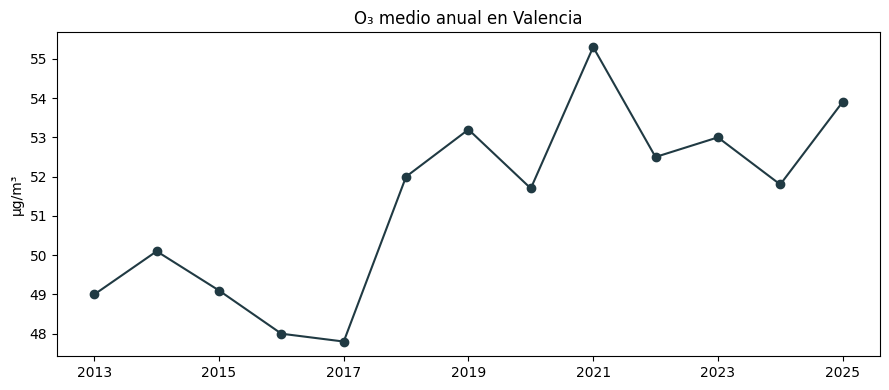

In [5]:
from google.cloud import storage

plt.figure(figsize=(9, 4))
plt.plot(anual["anio"], anual["o3_medio"], marker="o", color="#203A43")
plt.title("O₃ medio anual en Valencia")
plt.ylabel("µg/m³")
plt.xticks(range(2013, 2026, 2))
plt.tight_layout()

plt.savefig("/tmp/o3_evolucion_anual.png", dpi=300, bbox_inches="tight")
plt.show()

storage.Client().bucket("tfm_unir1").blob(
    "figuras/o3_evolucion_anual.png"
).upload_from_filename("/tmp/o3_evolucion_anual.png")

In [10]:
# calcular las superaciones de 120 mug/m3
superaciones = (
    maximos_diarios
    .groupBy("id_estacion")
    .agg(
        F.count("*").alias("dias_con_datos"),
        F.sum(F.when(F.col("maximo_8h") > 120, 1)
              .otherwise(0)).alias("dias_superacion"),
        F.round(F.max("maximo_8h"), 1).alias("maximo_8h")
    )
    .orderBy("id_estacion")
)

superaciones.show()

+-----------+--------------+---------------+---------+
|id_estacion|dias_con_datos|dias_superacion|maximo_8h|
+-----------+--------------+---------------+---------+
|   46250030|           335|              0|    108.8|
|   46250043|           356|              5|    130.5|
|   46250046|           347|              0|    109.3|
|   46250047|           358|              0|    100.1|
|   46250048|           356|              0|    114.9|
|   46250050|           356|              2|    121.8|
+-----------+--------------+---------------+---------+



In [15]:
# Serie histórica de superaciones por estación
historico = (superaciones_anuales
    .groupBy("anio")
    .agg(F.max("superaciones").alias("max_superaciones"),
        F.avg("superaciones").alias("media_superaciones"))
    .orderBy("anio").toPandas())

historico

,anio,max_superaciones,media_superaciones
0,2013,1,0.333333
1,2014,4,1.285714
2,2015,9,3.166667
3,2016,0,0.000000
4,2017,6,2.166667
5,2018,9,3.666667
6,2019,14,3.333333
7,2020,2,0.666667
8,2021,7,3.833333
9,2022,2,0.833333


## Regresión lineal

In [16]:
from sklearn.linear_model import LinearRegression

datos = historico.copy()

# Entrenamiento con todos los años disponibles
modelo_lineal = LinearRegression()
modelo_lineal.fit(datos[["anio"]],datos["max_superaciones"])

print("Cambio anual:",round(modelo_lineal.coef_[0], 2),"días/año")

# Previsión de 2026 a 2030
futuro = pd.DataFrame({"anio": range(2026, 2031)})

futuro["superaciones_previstas"] = (
    modelo_lineal.predict(futuro[["anio"]])
    .clip(min=0).round(1))

futuro

/opt/conda/miniconda3/lib/python3.10/site-packages/scipy/__init__.py:155: UserWarning: A NumPy version >=1.18.5 and <1.26.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


Cambio anual: -0.12 días/año


,anio,superaciones_previstas
0,2026,4.0
1,2027,3.8
2,2028,3.7
3,2029,3.6
4,2030,3.5


In [17]:
# evaluación
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

# Entrenamiento y prueba
train = historico[historico["anio"] <= 2024]
test = historico[historico["anio"] == 2025]

modelo_test = LinearRegression()
modelo_test.fit(train[["anio"]], train["max_superaciones"])

prediccion_2025 = max(
    0, modelo_test.predict(test[["anio"]])[0])

real_2025 = test["max_superaciones"].iloc[0]
referencia_2025 = historico.loc[
    historico["anio"] == 2024, "max_superaciones"].iloc[0]

print("Valor real 2025:", real_2025)
print("Predicción 2025:", round(prediccion_2025, 1))
print("MAE regresión:", round(abs(real_2025 - prediccion_2025), 2))
print("MAE referencia:", round(abs(real_2025 - referencia_2025), 2))

Valor real 2025: 3
Predicción 2025: 4.5
MAE regresión: 1.48
MAE referencia: 1


In [18]:
# Media de los tres años anteriores a 2025
train = historico[historico["anio"] <= 2024]

prediccion_media = train.tail(3)["max_superaciones"].mean()

real_2025 = historico.loc[
    historico["anio"] == 2025, "max_superaciones"].iloc[0]

print("Predicción 2025:", round(prediccion_media, 2))
print("Valor real 2025:", real_2025)
print("MAE media móvil:", round(abs(real_2025 - prediccion_media), 2))

Predicción 2025: 2.33
Valor real 2025: 3
MAE media móvil: 0.67


In [19]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

resultados = []

for anio in range(2018, 2026):
    train = historico[historico["anio"] < anio]
    real = historico.loc[historico["anio"] == anio, "max_superaciones"].iloc[0]

    modelo = LinearRegression()
    modelo.fit(train[["anio"]], train["max_superaciones"])

    pred_lineal = max(0, modelo.predict(pd.DataFrame({"anio": [anio]}))[0])
    pred_referencia = train["max_superaciones"].iloc[-1]
    pred_media = train["max_superaciones"].tail(3).mean()

    resultados.append({
        "anio": anio,
        "real": real,
        "regresion": pred_lineal,
        "referencia": pred_referencia,
        "media_movil": pred_media})

evaluacion = pd.DataFrame(resultados)

for nombre in ["regresion", "referencia", "media_movil"]:
    mae = mean_absolute_error(evaluacion["real"], evaluacion[nombre])
    print(nombre, "- MAE:", round(mae, 2), "días")

evaluacion.round(1)

regresion - MAE: 4.63 días
referencia - MAE: 4.12 días
media_movil - MAE: 3.88 días


,anio,real,regresion,referencia,media_movil
0,2018,9,5.8,6,5.0
1,2019,14,8.5,9,5.0
2,2020,2,12.7,14,9.7
3,2021,7,9.0,2,8.3
4,2022,2,8.9,7,7.7
5,2023,3,6.7,2,3.7
6,2024,2,5.6,3,4.0
7,2025,3,4.5,2,2.3


## Predicción de O3 hasta 2030

In [20]:
valores = historico["max_superaciones"].tolist()

predicciones = []
for anio in range(2026, 2031):
    previsto = sum(valores[-3:]) / 3

    predicciones.append({
        "anio": anio,
        "superaciones_previstas": round(previsto, 2)})

    valores.append(previsto)

futuro = pd.DataFrame(predicciones)
futuro

,anio,superaciones_previstas
0,2026,2.67
1,2027,2.56
2,2028,2.74
3,2029,2.65
4,2030,2.65


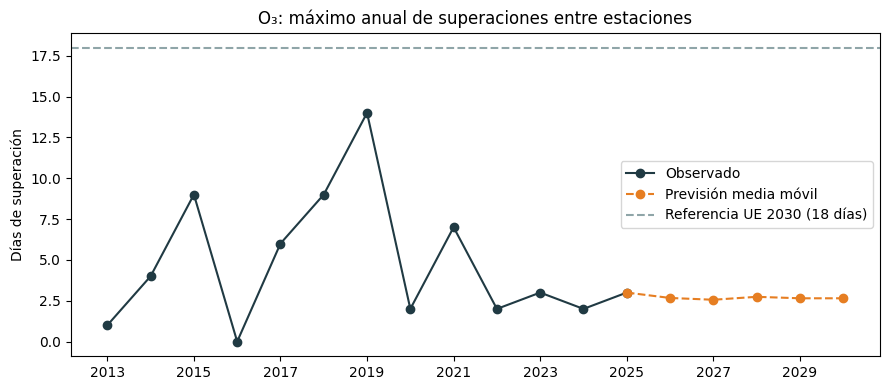

In [22]:
import matplotlib.pyplot as plt
from google.cloud import storage

plt.figure(figsize=(9, 4))
plt.plot(historico["anio"], historico["max_superaciones"],
         marker="o", color="#203A43", label="Observado")

# Unimos 2025 con la predicción de 2026
anios_pred = [2025] + futuro["anio"].tolist()
valores_pred = [historico["max_superaciones"].iloc[-1]] + futuro["superaciones_previstas"].tolist()

plt.plot(anios_pred, valores_pred,
         marker="o", linestyle="--", color="#E67E22",
         label="Previsión media móvil")

plt.axhline(18, color="#8FA5A8", linestyle="--",
            label="Referencia UE 2030 (18 días)")

plt.title("O₃: máximo anual de superaciones entre estaciones")
plt.ylabel("Días de superación")
plt.xticks(range(2013, 2031, 2))
plt.legend()
plt.tight_layout()

plt.savefig("/tmp/o3_prediccion_2030.png",
            dpi=300, bbox_inches="tight")
plt.show()

storage.Client().bucket("tfm_unir1").blob(
    "figuras/o3_prediccion_2030.png"
).upload_from_filename("/tmp/o3_prediccion_2030.png")

## Guardar en la capa Gold

In [23]:
from datetime import date

tabla_predicciones = pd.DataFrame({
    "modelo": "media_movil_3",
    "indicador": "o3_superaciones",
    "horizonte": "2030",
    "granularidad": "anual",
    "fecha_ejecucion": date.today(),
    "fecha_prevista": pd.to_datetime(
        futuro["anio"].astype(str) + "-01-01"
    ).dt.date,
    "id_tiempo": None,
    "id_estacion": None,
    "valor_previsto": futuro["superaciones_previstas"],
    "valor_bajo": None,
    "valor_alto": None})

tabla_predicciones

,modelo,indicador,horizonte,granularidad,fecha_ejecucion,fecha_prevista,id_tiempo,id_estacion,valor_previsto,valor_bajo,valor_alto
0,media_movil_3,o3_superaciones,2030,anual,2026-11-25,2026-01-01,None,None,2.67,None,None
1,media_movil_3,o3_superaciones,2030,anual,2026-11-25,2027-01-01,None,None,2.56,None,None
2,media_movil_3,o3_superaciones,2030,anual,2026-11-25,2028-01-01,None,None,2.74,None,None
3,media_movil_3,o3_superaciones,2030,anual,2026-11-25,2029-01-01,None,None,2.65,None,None
4,media_movil_3,o3_superaciones,2030,anual,2026-11-25,2030-01-01,None,None,2.65,None,None


In [25]:

pd.DataFrame.iteritems = pd.DataFrame.items

# Eliminamos temporalmente las columnas vacías
columnas = ["modelo", "indicador", "horizonte", "granularidad",
    "fecha_ejecucion", "fecha_prevista", "valor_previsto"]

spark.createDataFrame(
    tabla_predicciones[columnas]).createOrReplaceTempView("predicciones_o3")

# Guardamos en Gold
spark.sql("""
    INSERT INTO gold.fact_prediccion
    SELECT
        modelo,
        indicador,
        horizonte,
        granularidad,
        CAST(fecha_ejecucion AS DATE),
        CAST(fecha_prevista AS DATE),
        CAST(NULL AS INT),
        CAST(NULL AS STRING),
        CAST(valor_previsto AS DOUBLE),
        CAST(NULL AS DOUBLE),
        CAST(NULL AS DOUBLE),
        CAST(NULL AS INT)
    FROM predicciones_o3
""")

# Comprobamos
spark.sql("""
    SELECT modelo, indicador, COUNT(*) AS registros
    FROM gold.fact_prediccion
    WHERE indicador = 'o3_superaciones'
    GROUP BY modelo, indicador
""").show()

26/11/25 16:04:40 WARN SessionState: METASTORE_FILTER_HOOK will be ignored, since hive.security.authorization.manager is set to instance of HiveAuthorizerFactory.


+-------------+---------------+---------+
|       modelo|      indicador|registros|
+-------------+---------------+---------+
|media_movil_3|o3_superaciones|        5|
+-------------+---------------+---------+

